# Run SDM for Snowdon Beetle (*Chrysolina cerealis*): MaxEnt

*Section 11 — Case study: species distribution modelling, notebook 3 of 5.* Previous: `02_species_distribution_modelling`. Next: `04_random_forest_species_distribution_modelling`.

This notebook models the Snowdon beetle again, with **MaxEnt** (`rsgispy.modelling.species_distribution.MaxentClassifier`), the most widely used SDM method, using the same training data as the logistic regression of notebook 02. Notebook 05 compares the results of the logistic regression, MaxEnt and the random forest of notebook 04.

**What MaxEnt is.** MaxEnt (maximum entropy) was introduced as a machine-learning method that finds the most spread-out ("maximum entropy") distribution over the study area whose feature averages match those at the presences. It was later shown to be equivalent to an **inhomogeneous Poisson point-process model**: it models the *intensity* of records (expected records per unit area) as a log-linear function of the environment, and it can be fitted as a logistic regression of the presences against a large number of very heavily weighted background points (Fithian & Hastie 2013; Renner & Warton 2013). rsgispy follows the open-source `maxnet` formulation (Phillips et al. 2017), fitted with scikit-learn, so `MaxentClassifier` works with every function of the module.

**How it differs from notebook 02:**

* **Background, not absences.** MaxEnt contrasts the presences with *background* points that describe the environment available in the study area; it never treats them as places where the beetle is absent. Each background point gets a large weight (`bg_weight`, Default 100), which approximates the point-process limit.
* **Features.** Instead of one linear term per variable (plus the hand-made temperature² of notebook 02), MaxEnt expands each variable into many *features*: linear (`l`), quadratic (`q`), products of pairs (`p`), hinges (`h`, piecewise linear: 0 below a knot, rising above it, or the reverse) and thresholds (`t`, steps). Hinges let a response take almost any smooth shape.
* **Regularisation.** Every feature's coefficient is penalised (L1, so most are exactly 0), in proportion to how variable the feature is at the presences and to a `maxnet` table depending on the number of presences, multiplied by `beta_multiplier`: larger values give smoother models with fewer features.
* **Output.** `predict_proba` gives the **cloglog** output, `1 − exp(−exp(η + H))`, an estimate of the probability of presence in a pixel-sized area under some assumptions about prevalence; like notebook 02's output it is best read as **relative suitability**. Variables are **clamped** to their training range when predicting.

**You will learn:**
- how to choose MaxEnt's feature classes and regularisation (`maxent_default_feature_types`, `tune_maxent_beta`) with spatial cross-validation or AICc;
- how to fit, inspect (`selected_features_`), evaluate and interpret a MaxEnt model with the same tools as any other model;
- how MaxEnt's clamping affects projections to a warmer climate.

**Before you start:** run `01_prepare_datasets` and `02_species_distribution_modelling` (this notebook uses the training and test samples, and the scenario rasters, of notebook 02).

**Data:** from notebook 01: `outputs/Chrysolina_cerealis_presences.gpkg`, `outputs/valid_mask.tif`, `outputs/sdm_candidate_vars.json` and the images it lists. From notebook 02 (`outputs/sdm_LogReg_outs/`): `sdm_train.gpkg`, `sdm_test.gpkg` and the warmer temperature rasters `Mean_Winter_Temp_plus*.tif`.

**Run time:** about 2 minutes.

## Import Modules

In [1]:
import importlib.util
import os

import geopandas
import matplotlib.pyplot as plt
import numpy
import pandas
import rasterio
import rsgispy
import rsgispy.imagecalc.maths
import rsgispy.imageutils.colourtable
import rsgispy.mapping.raster
import rsgispy.modelling.species_distribution as species_distribution
import rsgispy.tools.jsonio
import rsgispy.tools.plotting
from IPython.display import Image, display
from rsgispy.ml.cv import SpatialBlockKFold

%matplotlib inline
pandas.set_option("display.max_columns", None)
pandas.set_option("display.width", 200)

## Define the Input Data and Output Directories

In [2]:
out_dir = "outputs/sdm_MaxEnt_outs"
plots_dir = os.path.join(out_dir, "plots")
os.makedirs(plots_dir, exist_ok=True)
lr_dir = "outputs/sdm_LogReg_outs"

presences_vec_file = "outputs/Chrysolina_cerealis_presences.gpkg"
presences_vec_lyr = "presences"
valid_msk_img = "outputs/valid_mask.tif"
cand_var_imgs = rsgispy.tools.jsonio.read_json_to_dict("outputs/sdm_candidate_vars.json")

env_vars = dict()
for var_name, img_file in cand_var_imgs.items():
    env_vars[var_name] = species_distribution.EnvVarInfo(
        name=var_name, file=img_file, band=1, data_type=rsgispy.VAR_TYPE_CONTINUOUS
    )
# The same seven variables as the logistic regression (elevation was dropped
# because of its collinearity with winter temperature).
analysis_vars = [var_name for var_name in env_vars if var_name != "elevation"]
analysis_vars

['calc_grass_dist',
 'flush_dist',
 'impr_grass_dist',
 'ledges_dist',
 'rock_dist',
 'scree_dist',
 'winter_temp']

## 1. Training Data: the Same Presences and Background as Notebook 02

A fair comparison of models needs the **same data**: we load the training and test samples saved by notebook 02, with their raw (un-standardised) values. MaxEnt scales the variables itself (to 0–1 with the training range), so no standardisation is needed.

**How many background points?** MaxEnt needs enough background points to describe the environment of the study area well: around 10 000 is the usual default. Notebook 02 already followed the same advice for its logistic regression (Barbet-Massin et al. 2012), drawing 10 000 points, 7000 of which are in the training set. The valid area is 425 449 pixels, so these are a 1.6 % sample of the pixels, spread over the whole study area. Using the *same* points for both models means that any difference between them comes from the models, not from different random draws. What differs is how they are used: notebook 02 weighted the classes equally (`class_weight="balanced"`); MaxEnt gives each background point a weight of 100, and we do not equalise or re-weight the classes. The pseudo-absences were drawn at least 40 m from any presence; MaxEnt does not need that exclusion (a background point may fall where the beetle lives), but at 40 m it removes very little of the study area.

In [3]:
train_vec_file = os.path.join(lr_dir, "sdm_train.gpkg")
test_vec_file = os.path.join(lr_dir, "sdm_test.gpkg")
train_gdf = geopandas.read_file(train_vec_file, layer="train")
test_gdf = geopandas.read_file(test_vec_file, layer="test")
test_y = test_gdf["clsid"].to_numpy()
n_train_pres = int(train_gdf["clsid"].sum())
print("Training:", train_gdf["clsid"].value_counts().to_dict())
print("Test:    ", test_gdf["clsid"].value_counts().to_dict())

Training: {0: 7000, 1: 23}
Test:     {0: 3000, 1: 11}


## 2. Feature Classes and Regularisation

### 2.1 The `maxnet` Default Feature Classes

With few presences, flexible features over-fit. `maxent_default_feature_types` returns `maxnet`'s default rule for a number of presences: linear only below 10 presences, plus quadratic from 10, hinges from 15 and products from 80.

In [4]:
for n_pres in [5, 12, n_train_pres, 100]:
    print(f"{n_pres:4d} presences: {species_distribution.maxent_default_feature_types(n_pres)}")

   5 presences: l
  12 presences: lq
  23 presences: lqh
 100 presences: lqph


With our 23 training presences the default is `"lqh"`: linear, quadratic and hinge features, but no products (too few presences to estimate interactions between pairs of variables).

### 2.2 Tuning `beta_multiplier` and the Feature Classes

`tune_maxent_beta` fits every combination of `beta_multipliers` and `feature_types` and scores it by the mean out-of-fold AUC of a cross-validation splitter. We use **the same spatial splitter as notebook 02** (1 km blocks, 3 folds), for the same reasons: the presences are strongly clustered, and random folds would reward models that memorise the sites. We try linear only (`"l"`), linear + quadratic (`"lq"`), linear + quadratic + hinge (`"lqh"`) and `"auto"` (the default, here also `"lqh"`, so it should give identical scores: a check). `n_coefs` is the number of non-zero coefficients of the model fitted to all the training samples, a measure of its complexity.

Highest spatial CV AUC: {'beta_multiplier': 0.5, 'feature_types': 'lqh'}


,beta_multiplier,feature_types,n_coefs,auc_mean,auc_sd,auc_se
0,0.5,l,6,0.935,0.007,0.004
1,1.0,l,6,0.936,0.008,0.005
2,2.0,l,4,0.932,0.011,0.006
3,3.0,l,4,0.933,0.009,0.005
4,4.0,l,3,0.933,0.008,0.005
5,0.5,lq,12,0.934,0.015,0.009
6,1.0,lq,10,0.937,0.008,0.005
7,2.0,lq,7,0.936,0.013,0.008
8,3.0,lq,5,0.934,0.014,0.008
9,4.0,lq,4,0.933,0.012,0.007


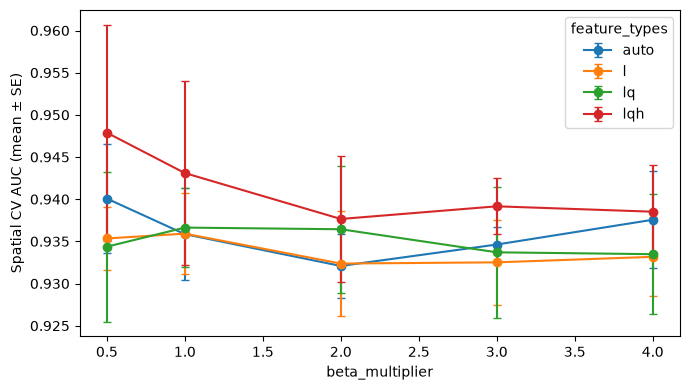

In [5]:
blk_cv = SpatialBlockKFold(n_splits=3, block_size=1000.0, stratify=True, rnd_seed=42)
tune_df, best_auc_params = species_distribution.tune_maxent_beta(
    train_gdf,
    None,
    analysis_vars,
    beta_multipliers=(0.5, 1.0, 2.0, 3.0, 4.0),
    feature_types=("l", "lq", "lqh", "auto"),
    cv=blk_cv,
    metric="auc",
    use_pbar=False,
)
tune_df["auc_se"] = tune_df["auc_sd"] / numpy.sqrt(3)
print("Highest spatial CV AUC:", best_auc_params)

fig, ax = plt.subplots(figsize=(7, 4))
for feat_type, feat_df in tune_df.groupby("feature_types"):
    ax.errorbar(feat_df["beta_multiplier"], feat_df["auc_mean"], yerr=feat_df["auc_se"],
                marker="o", capsize=3, label=feat_type)
ax.set_xlabel("beta_multiplier")
ax.set_ylabel("Spatial CV AUC (mean ± SE)")
ax.legend(title="feature_types")
fig.tight_layout()
tune_df.round(3)

All the settings score between 0.93 and 0.95: with 23 presences in three folds, the differences are small compared with their standard errors (0.003–0.013). The highest mean AUC is for hinge features with the weakest regularisation (`"lqh"`, `beta_multiplier` 0.5: 0.948, with 20 non-zero coefficients), but its advantage is within about one standard error of many simpler settings.

Why do `"auto"` and `"lqh"` differ, when `"auto"` means `"lqh"` for 23 presences? In cross-validation, `"auto"` applies the `maxnet` rule to the presences **of each fold's training data**: the folds hold out 5, 7 and 11 presences, so the models are trained on 18, 16 and 12 presences, and the last one gets only `"lq"`. A small illustration of how the defaults depend on sample size.

**AICc** (Akaike's information criterion corrected for small samples; Warren & Seifert 2011) is an alternative that needs no cross-validation: it balances the fit of a model to all the training presences against its number of non-zero coefficients. Lower is better.

In [6]:
aicc_df, best_aicc_params = species_distribution.tune_maxent_beta(
    train_gdf,
    None,
    analysis_vars,
    beta_multipliers=(0.5, 1.0, 2.0, 3.0, 4.0),
    feature_types=("l", "lq", "lqh"),
    metric="aicc",
    use_pbar=False,
)
print("Lowest AICc:", best_aicc_params)
aicc_df.sort_values("aicc").head(6).round(1)

Lowest AICc: {'beta_multiplier': 2.0, 'feature_types': 'lqh'}


,beta_multiplier,feature_types,aicc,n_coefs
12,2.0,lqh,328.0,10
13,3.0,lqh,328.2,8
14,4.0,lqh,329.1,6
8,3.0,lq,329.4,5
9,4.0,lq,330.4,4
7,2.0,lq,331.6,7


AICc also prefers linear + quadratic + hinge features with moderate to strong regularisation: `beta_multiplier` 2 (AICc 328.0, 10 coefficients), 3 (328.2, 8) and 4 (329.1, 6) are within about one unit of each other, and differences of less than about 2 are not meaningful. So the cross-validation and AICc agree on the type of model.

**The choice.** As in notebook 02, we use the one-standard-error rule: among the settings whose spatial CV AUC is within one standard error of the best, we choose the **simplest**, i.e. the one with the fewest non-zero coefficients (ties: the higher AUC). Simpler models have smoother responses and are more likely to transfer to other places and climates.

In [7]:
best_row = tune_df.loc[tune_df["auc_mean"].idxmax()]
ok_df = tune_df[tune_df["auc_mean"] >= best_row["auc_mean"] - best_row["auc_se"]]
sel_row = ok_df.sort_values(["n_coefs", "auc_mean"], ascending=[True, False]).iloc[0]
mx_params = {
    "beta_multiplier": float(sel_row["beta_multiplier"]),
    "feature_types": str(sel_row["feature_types"]),
}
rsgispy.tools.jsonio.write_dict_to_json(mx_params, os.path.join(out_dir, "maxent_params.json"))
print(f"Best AUC {best_row['auc_mean']:.3f} (SE {best_row['auc_se']:.3f}); selected {mx_params}: "
      f"AUC {sel_row['auc_mean']:.3f}, {int(sel_row['n_coefs'])} coefficients")

Best AUC 0.948 (SE 0.013); selected {'beta_multiplier': 4.0, 'feature_types': 'lqh'}: AUC 0.939, 6 coefficients


## 3. Fit the Model and Inspect Its Features

`fit_sklearn_mdl` fits the model (`return_model=True` returns it). `selected_features_` lists the features with non-zero coefficients: the whole model is the sum of these features × their coefficients (on the scale of the link, η). Feature names give the variable and, for hinges, the knot in the variable's units: `hinge_fwd(x, k)` is 0 below `k` and rises above it; `hinge_rev(x, k)` is 0 above `k` and rises below it. A negative coefficient on `hinge_fwd(ledges_dist, 500)`, for example, would mean "suitability falls once you are more than 500 m from a ledge".

In [8]:
mx_mdl, train_acc, test_acc, test_auc = species_distribution.fit_sklearn_mdl(
    est_cls_obj=species_distribution.MaxentClassifier(**mx_params),
    train_vec_file=train_gdf,
    train_vec_lyr=None,
    test_vec_file=test_gdf,
    test_vec_lyr=None,
    analysis_vars=analysis_vars,
    cls_col="clsid",
    return_model=True,
)
mx_mdl.selected_features_.round(3)

Classifier Train Score = 90.27%
Classifier Test Score = 90.44%


,feature,feature_class,coef
0,ledges_dist^2,q,-41.521
1,winter_temp^2,q,-9.163
2,"hinge_rev(flush_dist,1084.65)",h,-1.723
3,"hinge_rev(rock_dist,2541.16)",h,-0.116
4,"hinge_rev(scree_dist,641.596)",h,-0.324
5,"hinge_rev(winter_temp,2.70447)",h,-0.636


The one-standard-error rule selects `"lqh"` with `beta_multiplier` 4 (AUC 0.939, within one standard error of the best), a model with only **six features**:

* `ledges_dist^2` (coefficient −41.5): a quadratic decline away from the ledges, flat at a ledge and falling faster and faster with distance;
* `winter_temp^2` (−9.2) and `hinge_rev(winter_temp, 2.70)` (−0.6): a hump in temperature, with an extra penalty for temperatures colder than 2.70 °C;
* `hinge_rev(flush_dist, 1084.65)` (−1.7): suitability is reduced within about 1085 m of a flush, increasingly so closer to it, and is constant beyond;
* `hinge_rev(scree_dist, 641.6)` (−0.3) and `hinge_rev(rock_dist, 2541.2)` (−0.1): small reductions close to scree and to rock.

Calcareous grassland and improved grassland have **no** features: the L1 penalty has removed them from the model. The coefficients apply to the min-max scaled variables, so their sizes are not comparable with those of notebook 02.

## 4. Evaluate the Model

The same measures as notebook 02, on the same test points: AUC, TSS at the threshold maximising it, sensitivity and specificity, and the Boyce index; a null-model test of the AUC; and an ensemble fitted with the same spatial folds.

auc                     0.974
threshold               0.680
tss                     0.940
sensitivity             1.000
specificity             0.940
omission_rate           0.000
commission_rate         0.060
kappa                   0.103
accuracy                0.941
balanced_accuracy       0.970
prevalence              0.004
n_presence             11.000
n_absence            3000.000
boyce                   0.865
null_p95                0.652
null_p_value            0.010
dtype: float64

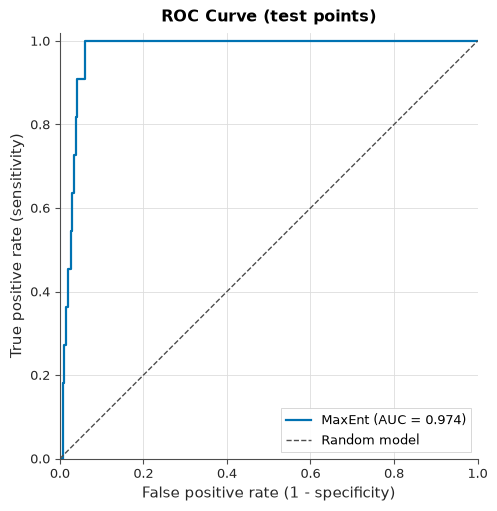

In [9]:
test_probs = species_distribution.get_positive_class_probs(mx_mdl, test_gdf[analysis_vars])
mx_metrics = species_distribution.calc_sdm_eval_metrics(test_y, test_probs, bg_scores="absences")
fpr, tpr, auc = species_distribution.calc_binary_roc_auc(test_y, test_probs)
fig, ax = species_distribution.plot_roc_curve(
    fpr, tpr, auc, label="MaxEnt", title="ROC Curve (test points)",
    out_plot_file=os.path.join(plots_dir, "maxent_testing_roc_curve.png"),
)
null_res = species_distribution.calc_null_model_auc(
    species_distribution.MaxentClassifier(**mx_params),
    train_gdf, None, test_gdf, None, analysis_vars,
    n_pres=n_train_pres, n_reps=99, observed_auc=mx_metrics["auc"], rnd_seed=42,
    plot_file=os.path.join(plots_dir, "maxent_null_model_auc.png"), use_pbar=False,
)
mx_metrics["null_p95"] = null_res["null_p95"]
mx_metrics["null_p_value"] = null_res["p_value"]
pandas.Series(mx_metrics).round(3)

On the test points MaxEnt has an AUC of 0.974 and a TSS of 0.940 (all 11 presences predicted present, 94 % of the pseudo-absences predicted absent at the threshold 0.680), and a Boyce index of 0.865. The null models reach a 95th percentile AUC of 0.652, far below the observed AUC (p = 0.01). These scores are slightly higher than those of the logistic regression (AUC 0.964, TSS 0.897), but with 11 test presences, differences of about 0.01 in AUC are within the noise; notebook 05 compares the models in detail.

In [10]:
mx_mdls, mx_scores_df = species_distribution.fit_kfold_sklearn_mdls(
    species_distribution.MaxentClassifier(**mx_params),
    train_gdf, None, test_gdf, None, analysis_vars,
    cv=blk_cv, rnd_seed=42, return_scores=True, use_pbar=False,
)
score_cols = ["val_auc", "val_tss", "val_boyce", "test_auc", "test_tss"]
print(mx_scores_df[["fold", "n_train", "n_val"] + score_cols].round(3))

ens_test_probs = numpy.median(
    [species_distribution.get_positive_class_probs(mdl, test_gdf[analysis_vars]) for mdl in mx_mdls],
    axis=0,
)
mx_ens_metrics = species_distribution.calc_sdm_eval_metrics(test_y, ens_test_probs, bg_scores="absences")
pandas.Series(mx_ens_metrics).round(3)

ROC: 0.9314242424242424 - 0.9743333333333334 - 0.977090909090909
Train: 0.8345446772124839 - 0.890881913303438 - 0.9331910352187833
Test: 0.8272999003653271 - 0.9030222517436067 - 0.9066755230820326
Validation (out-of-fold) ROC: 0.9291041577368195 - 0.9350315494274363 - 0.9515032759782011
   fold  n_train   n_val  val_auc  val_tss  val_boyce  test_auc  test_tss
0     0   4685.0  2338.0    0.929    0.886     -0.233     0.974     0.947
1     1   4683.0  2340.0    0.952    0.889      0.661     0.977     0.945
2     2   4678.0  2345.0    0.935    0.890      0.368     0.931     0.891


auc                     0.976
threshold               0.684
tss                     0.942
sensitivity             1.000
specificity             0.942
omission_rate           0.000
commission_rate         0.058
kappa                   0.106
accuracy                0.942
balanced_accuracy       0.971
prevalence              0.004
n_presence             11.000
n_absence            3000.000
boyce                   0.896
dtype: float64

The three spatial members have out-of-fold AUCs of 0.929, 0.952 and 0.935 (mean 0.939) and TSS of 0.89, very close to the logistic regression (0.941 and 0.86). As in notebook 02, the out-of-fold Boyce index is unstable with so few presences per fold (−0.23, 0.66, 0.37). The median of the three members has a test AUC of 0.976, TSS 0.942 and Boyce index 0.896.

In [11]:
resid_df = species_distribution.calc_residual_autocorrelation(
    mx_mdl, train_gdf, None, analysis_vars,
    dist_classes=[0, 250, 500, 1000, 1500, 2000, 3000, 4000, 6000],
    n_perms=99, rnd_seed=42,
)
resid_df[["dist_lower", "dist_upper", "morans_i", "p_value"]].round(3)

,dist_lower,dist_upper,morans_i,p_value
0,0.0,250.0,0.925,0.01
1,250.0,500.0,0.852,0.01
2,500.0,1000.0,0.681,0.01
3,1000.0,1500.0,0.473,0.01
4,1500.0,2000.0,0.328,0.01
5,2000.0,3000.0,0.163,0.01
6,3000.0,4000.0,0.007,0.01
7,4000.0,6000.0,-0.072,0.01


The residuals are autocorrelated over the same distances as those of the logistic regression (Moran's I 0.93 below 250 m, about 0 at 3–4 km): the flexibility of MaxEnt's hinges has not removed the spatial structure, so the same caution applies to its test scores.

## 5. Interpreting the MaxEnt Model

### 5.1 Response Curves

The same function as in notebook 02, here with raw values (`normalised_data=False`). Two things specific to MaxEnt: the y axis is the **cloglog** output, and with `clamp=True` (the default) a variable beyond its training range is treated as if it were at the end of the range, so the curves (and the map) stay flat beyond the training data instead of extrapolating.

calc_grass_dist Range:	(0.0 - 6102.75341796875): Mean = 1280.7439933445144
Calculating Response Curve for 'calc_grass_dist'
flush_dist Range:	(0.0 - 2214.497802734375): Mean = 929.4367184846298
Calculating Response Curve for 'flush_dist'
impr_grass_dist Range:	(0.0 - 3739.732666015625): Mean = 1950.0651271654212
Calculating Response Curve for 'impr_grass_dist'
ledges_dist Range:	(0.0 - 5341.947265625): Mean = 355.9866565206776
Calculating Response Curve for 'ledges_dist'
rock_dist Range:	(0.0 - 6917.6005859375): Mean = 2436.267542300017
Calculating Response Curve for 'rock_dist'
scree_dist Range:	(0.0 - 3493.13623046875): Mean = 493.25894231381625
Calculating Response Curve for 'scree_dist'
winter_temp Range:	(2.5071563720703125 - 4.4408345222473145): Mean = 2.8537858465443486
Calculating Response Curve for 'winter_temp'


,variable,min suitability,max suitability,at value,>= half max from,to
0,calc_grass_dist,0.87,0.87,0.00,0.00,6102.75
1,flush_dist,0.38,0.93,1090.56,178.05,2214.50
2,impr_grass_dist,0.87,0.87,0.00,0.00,3739.73
3,ledges_dist,0.00,0.92,0.00,0.00,966.38
4,rock_dist,0.84,0.88,2572.37,0.00,6917.60
5,scree_dist,0.80,0.89,649.48,0.00,3493.14
6,winter_temp,0.00,0.92,2.71,2.51,3.28


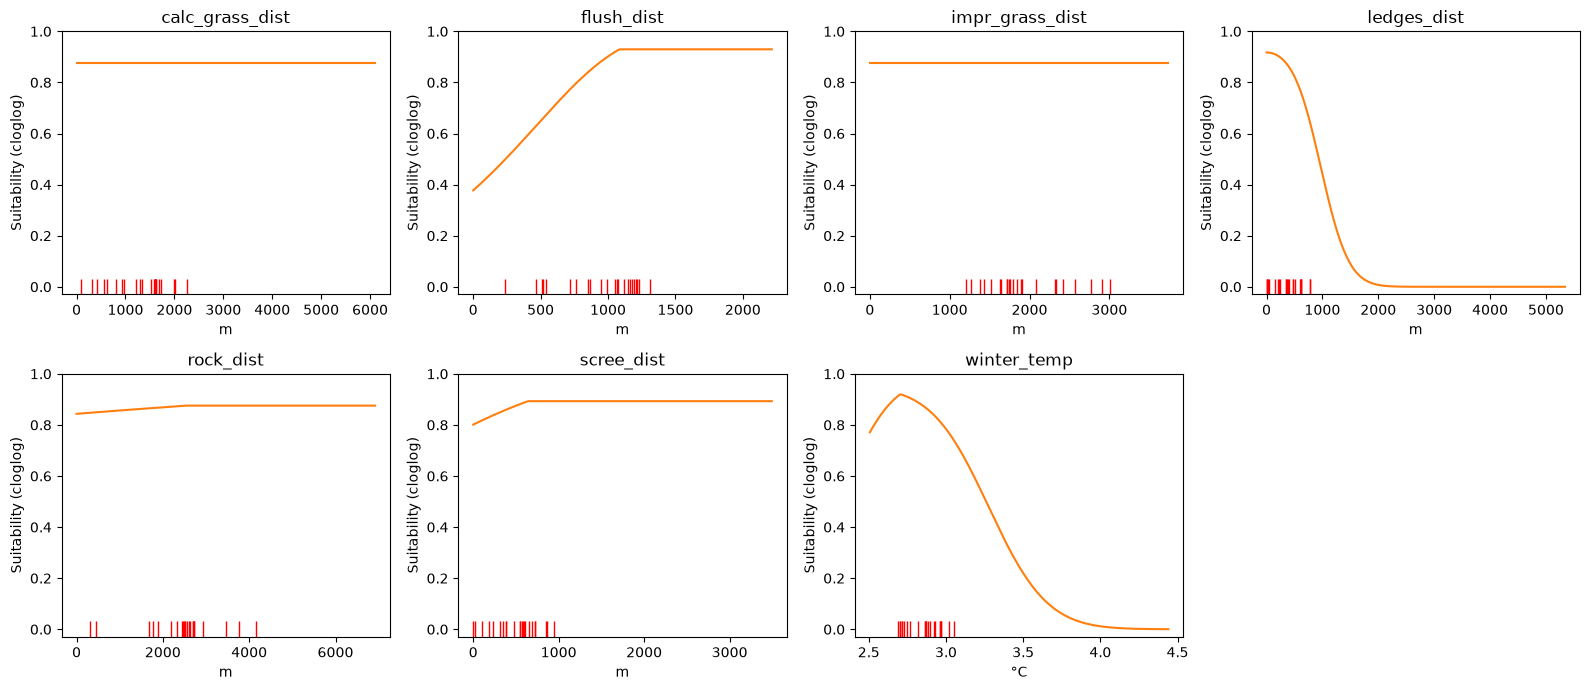

In [12]:
mx_resp_df = species_distribution.sklearn_mdl_variable_response_curves(
    est_cls_obj=mx_mdl,
    train_vec_file=train_gdf,
    train_vec_lyr=None,
    analysis_vars=analysis_vars,
    output_file=os.path.join(out_dir, "maxent_response_curves.csv"),
    response_plots_dir=None,
    n_samples=200,
    cls_col="clsid",
)
train_pres_gdf = train_gdf[train_gdf["clsid"] == 1]
units = {"winter_temp": "°C"}
fig, axs = plt.subplots(2, 4, figsize=(16, 7))
for ax, var_name in zip(axs.flatten(), analysis_vars):
    ax.plot(mx_resp_df[f"{var_name}_vals"], mx_resp_df[f"{var_name}_resp"], color="tab:orange")
    ax.plot(train_pres_gdf[var_name], numpy.zeros(len(train_pres_gdf)), "|", color="red", ms=12)
    ax.set_ylim(-0.03, 1.0)
    ax.set_title(var_name)
    ax.set_xlabel(units.get(var_name, "m"))
    ax.set_ylabel("Suitability (cloglog)")
axs.flatten()[-1].axis("off")
fig.tight_layout()

half_rows = []
for var_name in analysis_vars:
    vals = mx_resp_df[f"{var_name}_vals"].to_numpy()
    resp = mx_resp_df[f"{var_name}_resp"].to_numpy()
    above = vals[resp >= resp.max() / 2]
    half_rows.append({"variable": var_name, "min suitability": resp.min(), "max suitability": resp.max(),
                      "at value": vals[resp.argmax()], ">= half max from": above.min(), "to": above.max()})
pandas.DataFrame(half_rows).round(2)

The MaxEnt responses are made of the six features above, so they are smooth curves (the quadratic terms) joined to straight lines with kinks at the hinge knots, and they are flat beyond each knot:

* **Distance to ledges** — suitability is above half its maximum within about 970 m of a ledge and close to 0 beyond about 2 km, almost the same as the logistic regression (about 1050 m).
* **Winter temperature** — a hump with its peak at 2.71 °C, above half its maximum between 2.51 and 3.28 °C, falling more gradually than the logistic regression's on the warm side (to near 0 only above about 4 °C).
* **Distance to flushes** — 0.38 at a flush, rising in a straight line to 0.93 at 1085 m, and flat beyond: the hinge says "more than about 1 km from a flush makes no further difference", which is more plausible than the logistic regression's ever-rising curve.
* **Distance to scree** and **to rock** — small rises up to the hinge knots (640 m and 2.5 km) and flat beyond. The scree response has the same counter-intuitive direction as in the logistic regression (less suitable close to scree), but is much weaker (0.80 to 0.89).
* **Improved and calcareous grassland** — exactly flat (no features).

The suitability values are cloglog outputs (0.87–0.93 at the presence means); clamping keeps every curve flat beyond the training range.

### 5.2 Jackknife Variable Importance

In [13]:
mx_jk_df = species_distribution.sklearn_jackknife_var_importance(
    est_cls_obj=species_distribution.MaxentClassifier(**mx_params),
    train_vec_file=train_gdf,
    train_vec_lyr=None,
    test_vec_file=test_gdf,
    test_vec_lyr=None,
    analysis_vars=analysis_vars,
    out_var_importance_file=os.path.join(out_dir, "maxent_jackknife_var_importance.csv"),
    out_importance_auc_plot=os.path.join(plots_dir, "maxent_jackknife_auc.png"),
    cls_col="clsid",
    use_pbar=False,
)
print(f"Test AUC with all the variables: {mx_metrics['auc']:.3f}")
mx_jk_df[["roc_test_acc_leave_var_out", "roc_test_acc_only_var"]].round(3)

Test AUC with all the variables: 0.974


,roc_test_acc_leave_var_out,roc_test_acc_only_var
calc_grass_dist,0.974,0.470
flush_dist,0.950,0.897
impr_grass_dist,0.974,0.761
ledges_dist,0.954,0.893
rock_dist,0.974,0.826
scree_dist,0.970,0.597
winter_temp,0.969,0.834


On their own, the distances to flushes (AUC 0.897) and ledges (0.893), and winter temperature (0.834), are again the most informative. Rock exposures do much better alone than in the logistic regression (0.826 against 0.655): with hinge features, MaxEnt can fit a non-monotonic response to a single variable (most presences are 1.7–4 km from mapped rock), which one linear term cannot. Leaving out flushes (0.974 → 0.950) or ledges (0.954) lowers the AUC most, and temperature a little (0.969); leaving out any other variable changes nothing, which is consistent with the L1 penalty having removed or nearly removed them.

### 5.3 SHAP

MaxEnt is neither a tree model nor a linear model of its inputs (it is linear in its *features*), so SHAP uses its model-agnostic `KernelExplainer` on `predict_proba`: the SHAP values are on the **probability (cloglog) scale**, unlike the log-odds SHAP values of notebook 02. Kernel SHAP is slow (it evaluates the model on many perturbed copies of every sample, against a background sample), so we explain a small table: all 23 training presences and 177 randomly chosen background points. The same table is the explainer's background, so the reference ("average") prediction is that of this sample, in which presences are over-represented. `use_tree_explainer=False` stops rsgispy from trying the linear explainer, which would use MaxEnt's feature coefficients as if they were coefficients of the variables.

Using 200 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.


  0%|          | 0/200 [00:00<?, ?it/s]

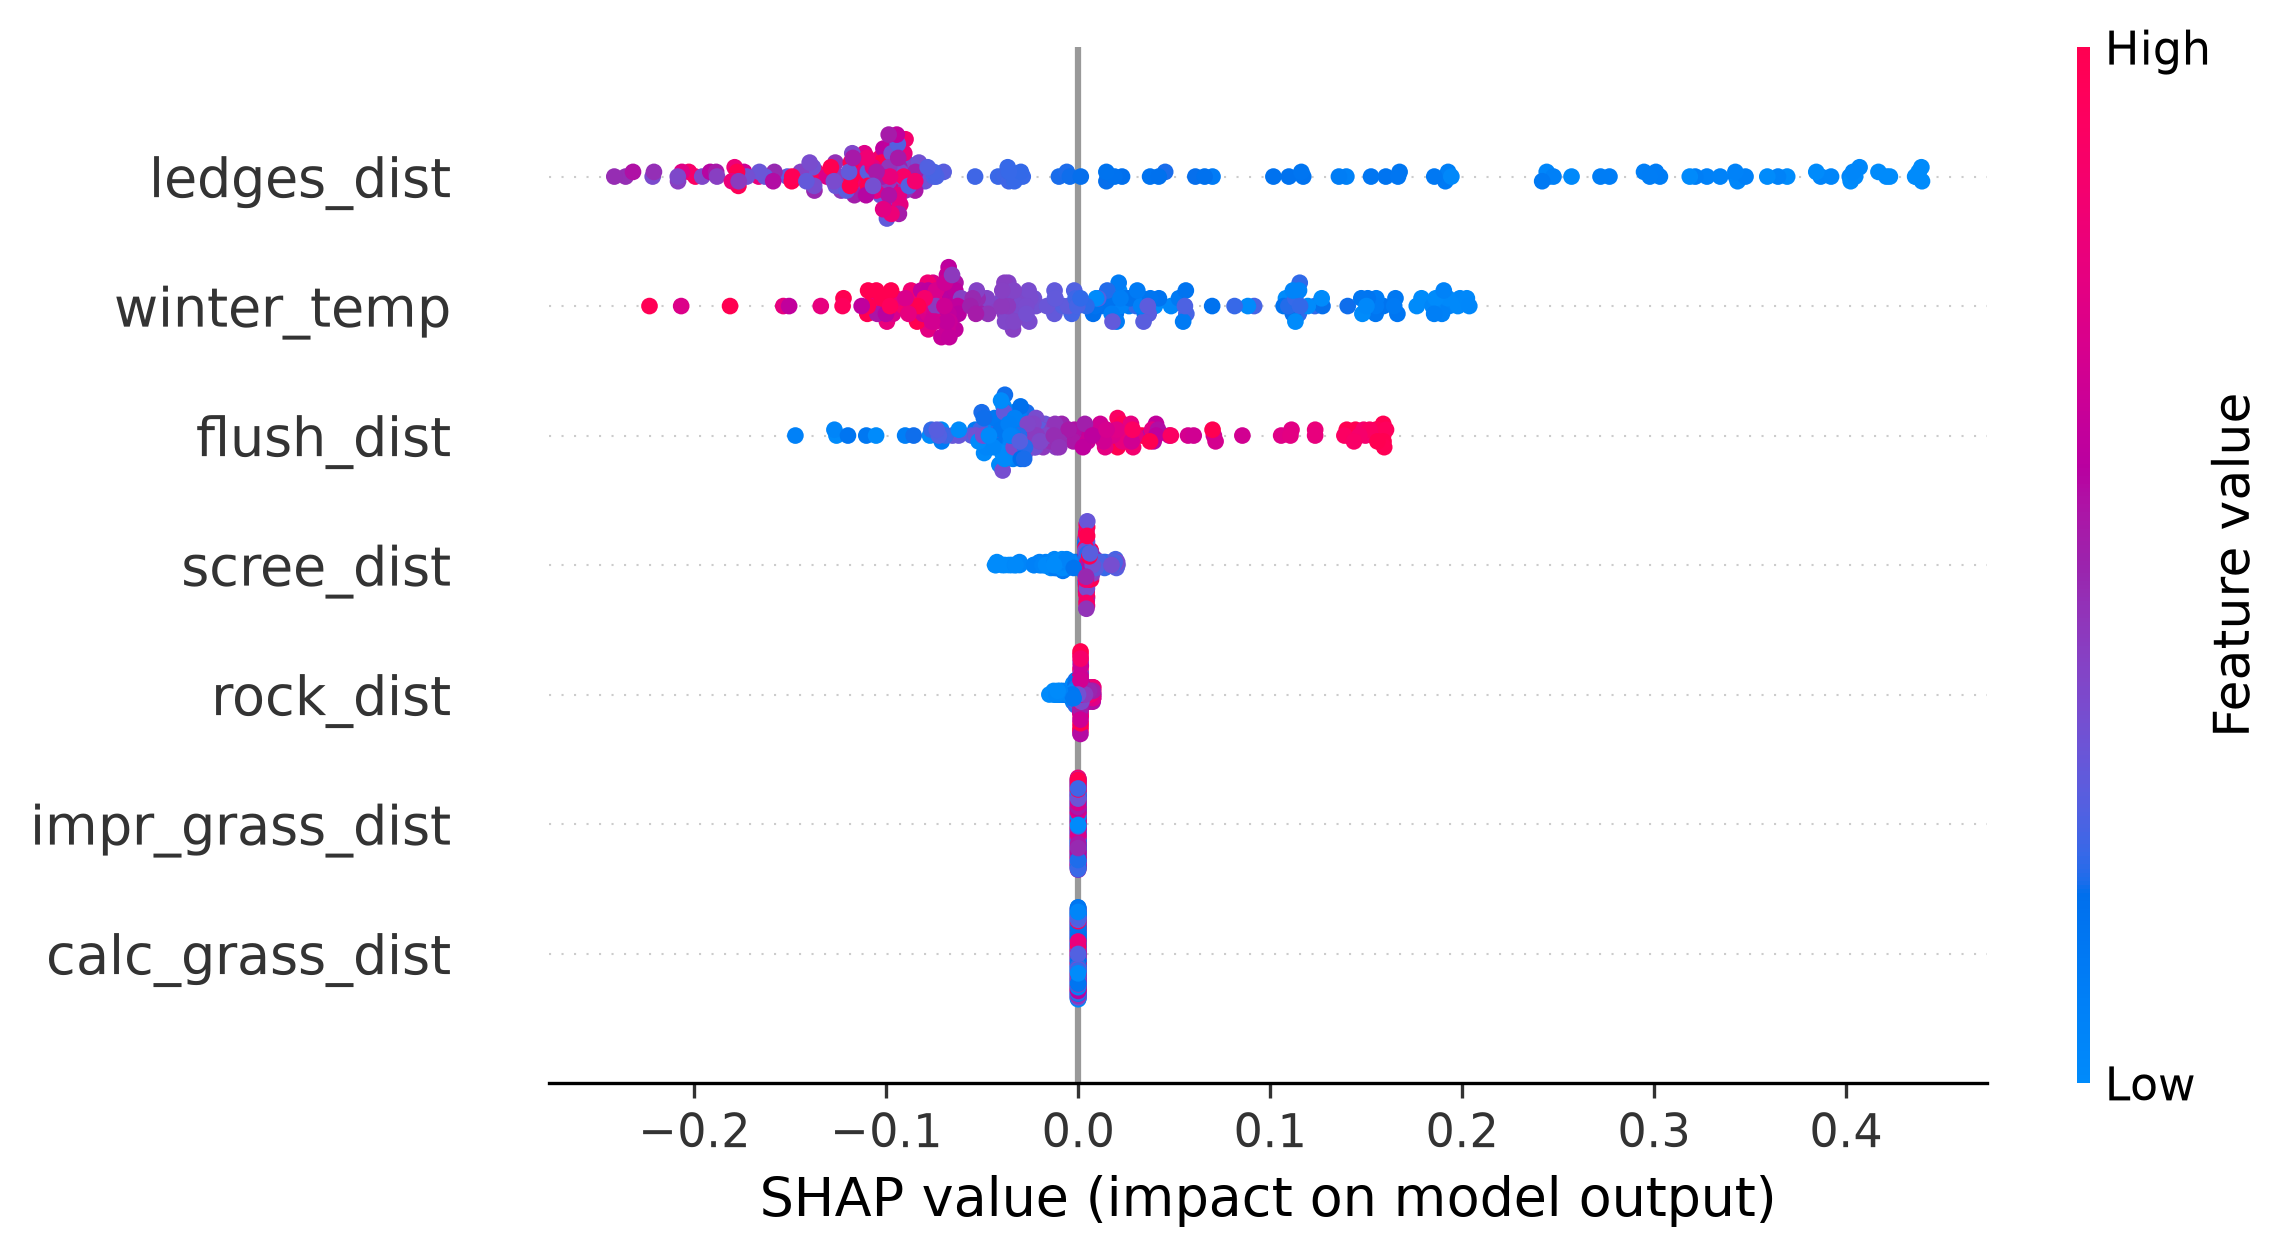

Using 200 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.


ledges_dist        0.1591
winter_temp        0.0780
flush_dist         0.0497
scree_dist         0.0094
rock_dist          0.0032
calc_grass_dist    0.0000
impr_grass_dist    0.0000
Name: mean |SHAP| (cloglog), dtype: float64

In [14]:
shap_gdf = pandas.concat(
    [
        train_gdf[train_gdf["clsid"] == 1],
        train_gdf[train_gdf["clsid"] == 0].sample(n=177, random_state=42),
    ]
)
if importlib.util.find_spec("shap") is not None:
    species_distribution.shap_sklearn_mdl_explainer(
        est_cls_obj=mx_mdl,
        train_vec_file=shap_gdf,
        train_vec_lyr=None,
        analysis_vars=analysis_vars,
        shap_summary_plot=os.path.join(plots_dir, "maxent_shap_summary.png"),
        use_tree_explainer=False,
        use_linear_explainer=False,
    )
    display(Image(filename=os.path.join(plots_dir, "maxent_shap_summary.png"), width=650))

    # The mean |SHAP| of each variable, for the comparison in notebook 05.
    import shap

    shap_x = shap_gdf[analysis_vars]
    kernel_exp = shap.KernelExplainer(lambda x: mx_mdl.predict_proba(
        pandas.DataFrame(x, columns=analysis_vars))[:, 1], shap_x)
    mx_shap_vals = kernel_exp.shap_values(shap_x, silent=True)
    mx_shap_df = pandas.Series(numpy.abs(mx_shap_vals).mean(axis=0), index=analysis_vars,
                               name="mean |SHAP| (cloglog)")
    display(mx_shap_df.sort_values(ascending=False).round(4))
else:
    print("The shap package is not installed, so the SHAP analysis is skipped.")

The SHAP values (on the cloglog scale) rank the distance to ledges first (mean |SHAP| 0.16), then winter temperature (0.08) and flushes (0.05); scree and rock have tiny values, and improved and calcareous grassland exactly 0, as they have no features. The summary plot shows the directions: being close to a ledge (blue) raises the prediction by up to about 0.44 for this sample, high temperatures (red) lower it, and being far from flushes (red) raises it. Since MaxEnt has no product features, the spread of SHAP values at a given value of a variable comes from the non-linear cloglog output, not from learnt interactions.

### 5.4 Sobol Sensitivity Analysis

On the probability (cloglog) scale, as in notebook 02. As there, interactions (ST > S1) can come from two sources: the non-linear output link (as for the logistic regression), and product features, if any were selected (here none: products need 80 presences in the default rule, and `"lqh"` has none).

In [15]:
if importlib.util.find_spec("SALib") is not None:
    mx_total_si, mx_first_si, mx_second_si = species_distribution.salib_sklearn_mdl_sensitivity(
        est_cls_obj=mx_mdl,
        train_vec_file=train_gdf,
        train_vec_lyr=None,
        analysis_vars=analysis_vars,
        n_samples=1024,
        sobol_overall_file=os.path.join(out_dir, "maxent_sobol_total.csv"),
        sobol_first_file=os.path.join(out_dir, "maxent_sobol_first_order.csv"),
        sobol_second_file=os.path.join(out_dir, "maxent_sobol_second_order.csv"),
        rnd_seed=42,
    )
    order = mx_total_si["ST"].sort_values(ascending=False).index
    display(pandas.concat([mx_total_si, mx_first_si], axis=1).loc[order].round(3))
    print("Largest second order (pairwise interaction) indices:")
    display(mx_second_si.sort_values("S2", ascending=False).head(5).round(3))
else:
    print("The SALib package is not installed, so the Sobol analysis is skipped.")

calc_grass_dist Range:	(0.0 - 6102.75341796875)
flush_dist Range:	(0.0 - 2214.497802734375)
impr_grass_dist Range:	(0.0 - 3739.732666015625)
ledges_dist Range:	(0.0 - 5341.947265625)
rock_dist Range:	(0.0 - 6917.6005859375)
scree_dist Range:	(0.0 - 3493.13623046875)
winter_temp Range:	(2.5071563720703125 - 4.4408345222473145)


,ST,ST_conf,S1,S1_conf
ledges_dist,0.874,0.121,0.436,0.116
winter_temp,0.536,0.101,0.098,0.058
flush_dist,0.071,0.023,-0.012,0.012
scree_dist,0.001,0.001,-0.001,0.004
rock_dist,0.000,0.000,0.000,0.001
calc_grass_dist,0.000,0.000,0.000,0.000
impr_grass_dist,0.000,0.000,0.000,0.000


Largest second order (pairwise interaction) indices:


,S2,S2_conf
"(ledges_dist, winter_temp)",0.434,0.230
"(flush_dist, winter_temp)",0.077,0.047
"(flush_dist, rock_dist)",0.062,0.039
"(flush_dist, impr_grass_dist)",0.062,0.039
"(flush_dist, scree_dist)",0.062,0.039


The distance to ledges dominates even more than in the logistic regression: ST 0.87 and S1 0.44, against ST 0.54 and S1 0.10 for temperature, and 0.07 for flushes; the other variables contribute nothing. Temperature acts mostly through its interaction with ledges (S2 = 0.43 ± 0.23): on the probability scale, temperature only matters where a ledge is close enough for the suitability to be high. As in notebook 02, this "interaction" comes from the output link (here cloglog), not from product features, which this model does not have. The small negative S1 of flushes (−0.012) and the identical S2 values of 0.06 for flushes paired with variables that have no effect are estimation noise (their confidence intervals include 0): second order indices need many more samples to be precise.

## 6. Predict the MaxEnt Suitability Map

The median cloglog output of the three-member spatial ensemble, with the standard deviation and interquartile range of the members, thresholded at the maximum-TSS threshold of the ensemble's test predictions (and the 10th percentile training presence threshold for comparison). No `normalise_data`: MaxEnt was trained on raw values.

In [16]:
mx_prob_img = os.path.join(out_dir, "Snowdon_Beetle_maxent_sdm_prob.tif")
species_distribution.pred_ensemble_sklearn_mdls_prob(
    mx_mdls, valid_msk_img, 1, env_vars, analysis_vars, mx_prob_img,
    gdalformat="GTIFF", calc_stats=True, uncertainty=["std", "iqr"], use_pbar=False,
)
ens_train_probs = numpy.median(
    [species_distribution.get_positive_class_probs(mdl, train_gdf[analysis_vars]) for mdl in mx_mdls],
    axis=0,
)
mx_thres = {
    "max TSS": species_distribution.calc_binary_threshold(test_y, ens_test_probs, method="max_tss"),
    "10th percentile training presence": float(
        numpy.percentile(ens_train_probs[train_gdf["clsid"] == 1], 10)
    ),
}
with rasterio.open(mx_prob_img) as src:
    mx_prob_arr = src.read(1)
    pxl_km2 = abs(src.res[0] * src.res[1]) / 1e6
valid = mx_prob_arr >= 0
thres_rows = []
for name, thres in mx_thres.items():
    test_bin = (ens_test_probs >= thres).astype(int)
    thres_rows.append({
        "threshold": name, "value": thres,
        "test sensitivity": test_bin[test_y == 1].mean(),
        "test specificity": 1 - test_bin[test_y == 0].mean(),
        "suitable area (km²)": (mx_prob_arr[valid] >= thres).sum() * pxl_km2,
        "% of study area": 100 * (mx_prob_arr[valid] >= thres).mean(),
    })
display(pandas.DataFrame(thres_rows).round(3))
mx_boyce = species_distribution.calc_boyce_index_from_raster(
    mx_prob_img, presences_vec_file, presences_vec_lyr, use_pbar=False
)
print(f"Boyce index of the map: {mx_boyce['boyce']:.3f}")

mx_bin_img = os.path.join(out_dir, "Snowdon_Beetle_maxent_sdm_bin.tif")
rsgispy.imagecalc.maths.band_maths(
    mx_bin_img,
    f"prob < 0 ? 255 : (prob >= {mx_thres['max TSS']} ? 1 : 0)",
    [rsgispy.imagecalc.maths.BandDefn("prob", mx_prob_img, 1)],
    gdalformat="GTIFF", datatype=rsgispy.TYPE_8UINT, no_data_val=255, use_pbar=False,
)

,threshold,value,test sensitivity,test specificity,suitable area (km²),% of study area
0,max TSS,0.684,1.0,0.942,10.167,5.974
1,10th percentile training presence,0.567,1.0,0.914,14.390,8.456


Boyce index of the map: 0.882


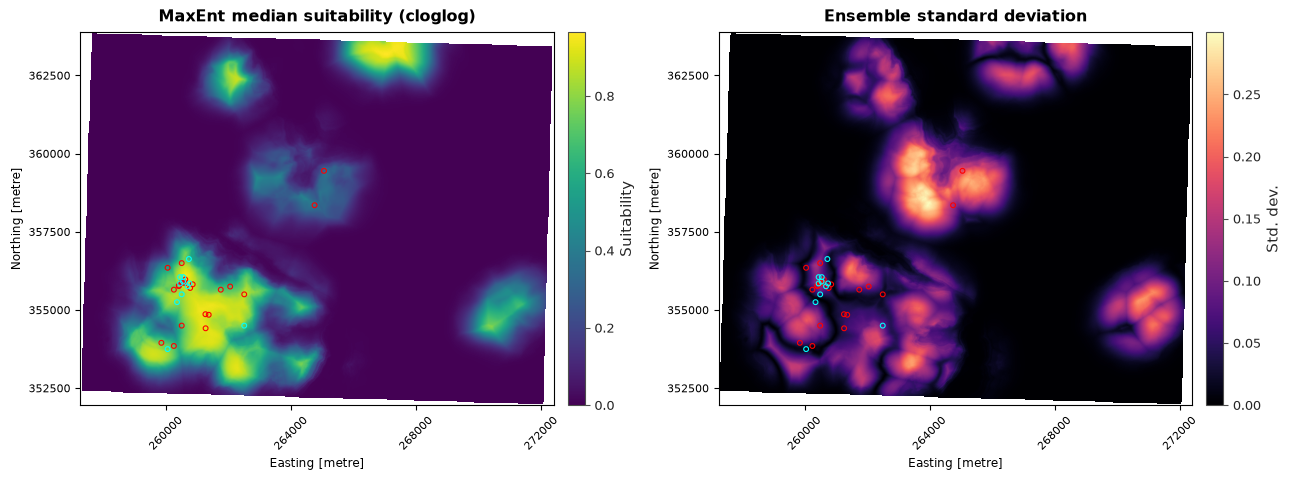

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for ax, (band, title, cmap, label) in zip(
    axs, [(1, "MaxEnt median suitability (cloglog)", "viridis", "Suitability"),
          (2, "Ensemble standard deviation", "magma", "Std. dev.")]
):
    rsgispy.mapping.raster.create_raster_cmap_img_map(
        ax, input_img=mx_prob_img, img_band=band, title_str=title, cmap_name=cmap,
        show_colour_bar=True, cbar_label=label, show_scale_bar=False,
    )
    train_pres_gdf.plot(ax=ax, facecolor="none", edgecolor="red", markersize=12, linewidth=0.8)
    test_gdf[test_gdf["clsid"] == 1].plot(ax=ax, facecolor="none", edgecolor="cyan", markersize=12, linewidth=0.8)
    ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()

The MaxEnt map shows the same main suitable areas as the logistic regression (Yr Wyddfa, and patches in the north and east), with the central area around the two isolated records less suitable. The ensemble members disagree most (highest standard deviation) over the central, northern and eastern patches, i.e. away from the cluster of training presences: these predictions depend on which blocks of presences a member was trained on.

The maximum-TSS threshold (0.684) predicts 10.2 km² (6.0 % of the study area) suitable, with all 11 test presences inside it; the 10th percentile training presence threshold (0.567) gives 14.4 km² (8.5 %). The Boyce index of the map is 0.882.

## 7. Projecting to a Warmer Climate: Clamping

Notebook 02 projected the logistic regression to winters 0.5 °C and 1 °C warmer (remember that, with the weak altitudinal gradient of this temperature raster, these are large changes; notebook 02, section 16). Here we project the MaxEnt ensemble to the same scenarios, thresholded with its own current maximum-TSS threshold.

MESS depends only on the training samples and the rasters, not on the model, so the areas outside the training range are the same as in notebook 02 (6.6 % of the study area at +0.5 °C, 34 % at +1 °C). What differs is what the model does there: MaxEnt **clamps** each variable to its training range, so a pixel warmer than the warmest training sample is predicted as if it had the warmest training temperature, whereas the logistic regression's parabola keeps falling.

In [18]:
scen_rows = []
for warming in [0.5, 1.0]:
    tag = f"plus{warming:.1f}".replace(".", "_")
    warm_temp_img = os.path.join(lr_dir, f"Mean_Winter_Temp_{tag}.tif")
    warm_env_vars = species_distribution.copy_env_vars_for_scenario(
        env_vars, {"winter_temp": warm_temp_img}
    )
    warm_prob_img = os.path.join(out_dir, f"Snowdon_Beetle_maxent_sdm_prob_{tag}.tif")
    species_distribution.pred_ensemble_sklearn_mdls_prob(
        mx_mdls, valid_msk_img, 1, warm_env_vars, analysis_vars, warm_prob_img,
        calc_stats=True, use_pbar=False,
    )
    warm_bin_img = os.path.join(out_dir, f"Snowdon_Beetle_maxent_sdm_bin_{tag}.tif")
    rsgispy.imagecalc.maths.band_maths(
        warm_bin_img,
        f"prob < 0 ? 255 : (prob >= {mx_thres['max TSS']} ? 1 : 0)",
        [rsgispy.imagecalc.maths.BandDefn("prob", warm_prob_img, 1)],
        gdalformat="GTIFF", datatype=rsgispy.TYPE_8UINT, no_data_val=255, use_pbar=False,
    )
    summary = species_distribution.calc_range_change(
        mx_bin_img, warm_bin_img, os.path.join(out_dir, f"maxent_range_change_{tag}.tif"),
        in_msk_img=valid_msk_img, use_pbar=False,
    )
    scen_rows.append(
        {
            "warming (°C)": warming,
            "current (km²)": summary["current_area"] / 1e6,
            "scenario (km²)": summary["future_area"] / 1e6,
            "lost (km²)": summary["area_lost"] / 1e6,
            "gained (km²)": summary["area_gained"] / 1e6,
            "stable (km²)": summary["area_stable"] / 1e6,
            "net change (%)": summary["pct_net_change"],
        }
    )
scen_df = pandas.DataFrame(scen_rows)
scen_df.round(2)

,warming (°C),current (km²),scenario (km²),lost (km²),gained (km²),stable (km²),net change (%)
0,0.5,10.17,1.72,8.45,0.0,1.72,-83.13
1,1.0,10.17,0.00,10.17,0.0,0.00,-100.00


With +0.5 °C, MaxEnt's suitable area falls from 10.2 km² to 1.7 km² (−83 %), all of it on ground that is suitable now (no gains), and with +1 °C nothing remains suitable: almost the same result as the logistic regression (−86 % and −100 %).

Clamping makes no difference here, and it is worth seeing why. The suitable area is lost on the high ground, where the warmer temperatures are still **within** the training range (they become like today's temperatures on the lower slopes, which the model has learnt are unsuitable). Clamping only changes the predictions for pixels warmer than any training sample, i.e. the warmest valley floors, which are unsuitable under both models anyway. So the projected loss is not an extrapolation artefact of one model: it follows from the narrow temperature band of the presences, which both models learn. The caveats of notebook 02 still apply in full (the weak lapse rate of this temperature raster, and the confounding of temperature with altitude).

## 8. Save the Results for the Comparison

Notebook 05 compares the three models (logistic regression, MaxEnt and random forest). It needs the test-set predictions, the cross-validation scores and the interpretation results of each, in the same format.

In [19]:
mx_metrics_out = {key: float(val) for key, val in mx_metrics.items()}
rsgispy.tools.jsonio.write_dict_to_json(mx_metrics_out, os.path.join(out_dir, "maxent_test_metrics.json"))
rsgispy.tools.jsonio.write_dict_to_json(mx_thres, os.path.join(out_dir, "maxent_thresholds.json"))
pandas.DataFrame({"clsid": test_y, "ens_prob": ens_test_probs}).to_csv(
    os.path.join(out_dir, "maxent_test_scores.csv"), index=False
)
mx_scores_df.to_csv(os.path.join(out_dir, "maxent_spatial_cv_scores.csv"), index=False)
scen_df.to_csv(os.path.join(out_dir, "maxent_scenarios.csv"), index=False)
if importlib.util.find_spec("SALib") is not None:
    mx_total_si.to_csv(os.path.join(out_dir, "maxent_sobol_ST.csv"), index_label="variable")
if importlib.util.find_spec("shap") is not None:
    mx_shap_df.rename("mean_abs_shap").to_csv(
        os.path.join(out_dir, "maxent_shap_mean_abs.csv"), index_label="variable"
    )
sorted(os.listdir(out_dir))

['Snowdon_Beetle_maxent_sdm_bin.tif',
 'Snowdon_Beetle_maxent_sdm_bin_plus0_5.tif',
 'Snowdon_Beetle_maxent_sdm_bin_plus1_0.tif',
 'Snowdon_Beetle_maxent_sdm_prob.tif',
 'Snowdon_Beetle_maxent_sdm_prob_plus0_5.tif',
 'Snowdon_Beetle_maxent_sdm_prob_plus1_0.tif',
 'maxent_jackknife_var_importance.csv',
 'maxent_params.json',
 'maxent_range_change_plus0_5.tif',
 'maxent_range_change_plus1_0.tif',
 'maxent_response_curves.csv',
 'maxent_scenarios.csv',
 'maxent_shap_mean_abs.csv',
 'maxent_sobol_ST.csv',
 'maxent_sobol_first_order.csv',
 'maxent_sobol_second_order.csv',
 'maxent_sobol_total.csv',
 'maxent_spatial_cv_scores.csv',
 'maxent_test_metrics.json',
 'maxent_test_scores.csv',
 'maxent_thresholds.json',
 'plots']